<!-- open-in-badges -->
[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/05_sequences/notebooks/sesion_05_3_lstm_gru.ipynb) [![Abrir en Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/05_sequences/notebooks/sesion_05_3_lstm_gru.ipynb) [![Abrir en Lightning Studio](https://pl-bolts-doc-images.s3.us-east-2.amazonaws.com/app-2/studio-badge.svg)](https://lightning.ai/new?repo_url=https%3A%2F%2Fgithub.com%2FEAFIT-IA%2Fsi7011-DeepLearning%2Fblob%2Fmain%2Fsessions%2F05_sequences%2Fnotebooks%2Fsesion_05_3_lstm_gru.ipynb)

# SI7011 · Sesión 05 · 3. LSTM y GRU: un camino aditivo para la memoria
**Juan David Martínez Vargas · Universidad EAFIT**

Acompaña la **Parte 3** de las diapositivas. La misma tarea de los notebooks 1 y 2 (5 días de Jena → temperatura en 24 horas), ahora con celdas que tienen un camino **aditivo** a lo largo del tiempo:

$$
\mathbf c_t = \mathbf f_t \odot \mathbf c_{t-1} + \mathbf i_t \odot \tilde{\mathbf c}_t
$$

| Sección | Lo que cambia | Qué mirar |
|---|---|---|
| 1 | la celda LSTM escrita a mano | que da lo mismo que `nn.LSTM` |
| 2 | LSTM en Jena | ¿le gana a la RNN y a la línea base? |
| 3 | GRU en Jena | menos parámetros, ¿mismo resultado? |
| 4 | el gradiente por hora: RNN, LSTM y GRU | ¿cambia la **forma** de la curva? |
| 5 | LSTM con 1 día frente a 5 días | si el gradiente llega, ¿sirven los días extra? |
| 6 | dos capas y *dropout* entre capas | apilar |

**Datos:** Jena Climate, misma partición y mismas ventanas de los notebooks 1 y 2. Corre en CPU en unos 4 minutos. **En Kaggle:** agrega el dataset [`mnassrib/jena-climate`](https://www.kaggle.com/datasets/mnassrib/jena-climate) con **Add Input**.

In [1]:
import json, time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

torch.manual_seed(0)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
print('PyTorch', torch.__version__)

PyTorch 2.14.1+cu130


## Datos: Jena, como en los notebooks 1 y 2
Misma carga y mismo contrato de datos (marcas de tiempo repetidas, errores del anemómetro, huecos), misma partición y mismas ventanas de $T = 120$ horas.

### Cargar Jena Climate
La celda busca `jena_climate_2009_2016.csv` en este orden y usa el primero que encuentre. Imprime la **fuente** usada: revísala.

| Plataforma | De dónde salen los datos |
|---|---|
| **Kaggle** | el dataset [`mnassrib/jena-climate`](https://www.kaggle.com/datasets/mnassrib/jena-climate) agregado con **Add Input** (`/kaggle/input/...`), sin descargar |
| **Lightning Studio** o **local** | la carpeta `data/` junto al notebook |
| **Colab** | `kagglehub` con el mismo dataset y tu secreto `KAGGLE_API_TOKEN` (el mismo de la sesión 01) |

In [2]:
import os
from pathlib import Path

KAGGLE_HANDLE = 'mnassrib/jena-climate'
ARCHIVO = 'jena_climate_2009_2016.csv'
ROOTS = [Path('data'), Path('/kaggle/input'), Path('/teamspace/studios/this_studio/data')]

def kaggle_token():
    # Colab: secreto KAGGLE_API_TOKEN. Local o Lightning: variable de entorno o ~/.kaggle/access_token.
    if 'KAGGLE_API_TOKEN' not in os.environ:
        try:
            from google.colab import userdata
            os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN').strip()
        except Exception:
            pass
    return 'KAGGLE_API_TOKEN' in os.environ or (Path.home() / '.kaggle' / 'access_token').exists()

def buscar_csv():
    for root in ROOTS:
        if root.exists():
            hits = sorted(root.rglob(ARCHIVO))
            if hits:
                return hits[0], str(root)
    if kaggle_token():
        import kagglehub
        path = Path(kagglehub.dataset_download(KAGGLE_HANDLE))
        return sorted(path.rglob(ARCHIVO))[0], f'kagglehub {KAGGLE_HANDLE}'
    raise FileNotFoundError(f'No encontré {ARCHIVO}: agrégalo con Add Input (Kaggle), ponlo en data/ o configura KAGGLE_API_TOKEN.')

ruta, fuente = buscar_csv()
print('fuente:', fuente, '·', ruta)
with open(ruta) as f:
    COLUMNAS = [c.strip('"') for c in f.readline().strip().split(',')][1:]   # sin 'Date Time'
crudo = np.loadtxt(ruta, delimiter=',', skiprows=1, usecols=range(1, 15), dtype=np.float32)
# El anemómetro marca −9999 cuando falla. Una velocidad negativa no existe: se reemplaza por 0 (sin viento).
VIENTO = [COLUMNAS.index('wv (m/s)'), COLUMNAS.index('max. wv (m/s)')]
errores = crudo[:, VIENTO] < 0
crudo[:, VIENTO] = np.where(errores, 0.0, crudo[:, VIENTO])
fechas = np.loadtxt(ruta, delimiter=',', skiprows=1, usecols=0, dtype=str)            # 'dd.mm.aaaa hh:mm:ss'
iso = np.array([f'{f[6:10]}-{f[3:5]}-{f[0:2]}T{f[11:19]}' for f in fechas], dtype='datetime64[s]')

# Contrato de datos: una fila por instante y una lectura por hora, elegida por su marca de tiempo (minuto :00),
# no por su posición en el archivo. Así no importa si la copia tiene filas repetidas o le faltan algunas.
_, primera = np.unique(iso, return_index=True)                 # quita marcas de tiempo repetidas (se queda con la primera)
primera = np.sort(primera)
en_punto = (iso[primera].astype('datetime64[m]') - iso[primera].astype('datetime64[h]')) == np.timedelta64(0, 'm')
filas = primera[en_punto]
datos, horas = crudo[filas], iso[filas].astype('datetime64[h]')
temp = datos[:, COLUMNAS.index('T (degC)')]
saltos = np.diff(horas) != np.timedelta64(1, 'h')
print(f'{len(crudo):,} lecturas cada 10 min · {len(iso) - len(primera)} marcas de tiempo repetidas (quitadas) · {int(errores.sum())} lecturas de viento = −9999 (puestas en 0)')
print(f'{len(datos):,} horas · {datos.shape[1]} variables · {int(saltos.sum())} huecos en la serie horaria')

fuente: data · data/jena_climate_2009_2016.csv


420,551 lecturas cada 10 min · 327 marcas de tiempo repetidas (quitadas) · 38 lecturas de viento = −9999 (puestas en 0)
70,037 horas · 14 variables · 4 huecos en la serie horaria


In [3]:
N = len(datos)
I_VAL, I_TEST = int(0.5 * N), int(0.75 * N)            # 50 % train · 25 % validación · 25 % prueba, en orden
T, H_FUT = 120, 24                                     # 5 días de entrada → temperatura 24 h después
mu, sd = datos[:I_VAL].mean(0), datos[:I_VAL].std(0)   # estadísticos SOLO del pasado (train)
Xn = (datos - mu) / sd
J_T = COLUMNAS.index('T (degC)')

def inicios(a, b, T=T):
    """Inicios de ventana cuyo objetivo (t + T - 1 + H_FUT) cae dentro del bloque [a, b),
    y que no saltan un hueco de la serie: de la primera hora al objetivo hay exactamente T - 1 + H_FUT horas."""
    ini = np.arange(a, b - T - H_FUT + 1)
    seguidas = (horas[ini + T - 1 + H_FUT] - horas[ini]) == np.timedelta64(T - 1 + H_FUT, 'h')
    return ini[seguidas]

tr, va, te = inicios(0, I_VAL), inicios(I_VAL, I_TEST), inicios(I_TEST, N)
base_val = np.abs(temp[va + T - 1] - temp[va + T - 1 + H_FUT]).mean()
print(f'{len(tr):,} ventanas de train · línea base {base_val:.2f} °C (notebook 1)')

34,732 ventanas de train · línea base 2.44 °C (notebook 1)


## Herramientas: ventanas, loop y MAE
Las mismas de los notebooks 1 y 2, más un modelo recurrente con la celda como parámetro y la medición del gradiente por hora del notebook 2.

In [4]:
class Ventanas(torch.utils.data.Dataset):
    """x = T horas de las 14 variables normalizadas; y = temperatura normalizada H_FUT horas después."""
    def __init__(self, inicios, T=T):
        self.inicios, self.T = inicios, T
    def __len__(self):
        return len(self.inicios)
    def __getitem__(self, i):
        a = self.inicios[i]
        return torch.from_numpy(Xn[a:a + self.T]), torch.tensor(Xn[a + self.T - 1 + H_FUT, J_T])

def cargador(inicios, T=T, barajar=False):
    return torch.utils.data.DataLoader(Ventanas(inicios, T), batch_size=256, shuffle=barajar)

@torch.no_grad()
def mae(modelo, inicios, T=T):
    """MAE en °C: el modelo predice la temperatura normalizada; se desnormaliza con sd de train."""
    modelo.eval()
    errores = [(modelo(x) - y).abs() for x, y in cargador(inicios, T)]
    return float(torch.cat(errores).mean().item() * sd[J_T])

def entrenar(modelo, inicios_train, inicios_val, T=T, epocas=8, lr=3e-3, recortar=1.0, normas=None):
    opt = torch.optim.Adam(modelo.parameters(), lr)
    t0 = time.time()
    for ep in range(epocas):
        modelo.train()
        for x, y in cargador(inicios_train, T, barajar=True):
            loss = nn.functional.mse_loss(modelo(x), y)
            opt.zero_grad(); loss.backward()
            norma = nn.utils.clip_grad_norm_(modelo.parameters(), recortar)   # devuelve la norma ANTES de recortar
            if normas is not None:
                normas.append(norma.item())
            opt.step()
        print(f'época {ep + 1}: MAE validación {mae(modelo, inicios_val, T):.3f} °C')
    print(f'{time.time() - t0:.0f} s · {sum(p.numel() for p in modelo.parameters()):,} parámetros')
    return modelo


class Recurrente(nn.Module):
    """Una celda recurrente (nn.RNN, nn.LSTM o nn.GRU) y una capa lineal sobre el último estado h_T."""
    def __init__(self, celda, oculta=16, capas=1, dropout=0.0):
        super().__init__()
        self.rnn = celda(14, oculta, num_layers=capas, dropout=dropout, batch_first=True)
        self.salida = nn.Linear(oculta, 1)
    def forward(self, x):
        h, _ = self.rnn(x)                         # la LSTM también devuelve c, que aquí no usamos
        return self.salida(h[:, -1]).squeeze(-1)

def gradiente_por_hora(modelo, n=256):
    modelo.eval()
    x, y = next(iter(cargador(va[::7][:n])))
    x = x.clone().requires_grad_(True)
    nn.functional.mse_loss(modelo(x), y).backward()
    return x.grad.norm(dim=2).mean(0).numpy()      # ‖∂L/∂x_t‖, promedio sobre 256 ventanas

resultados = {}

## 1. La celda LSTM, escrita a mano
Tres compuertas y un candidato, todos de $[\mathbf h_{t-1}, \mathbf x_t]$:

$$
\mathbf f_t, \mathbf i_t, \mathbf o_t = \sigma(\cdot), \qquad
\tilde{\mathbf c}_t = \tanh(\cdot), \qquad
\mathbf c_t = \mathbf f_t \odot \mathbf c_{t-1} + \mathbf i_t \odot \tilde{\mathbf c}_t, \qquad
\mathbf h_t = \mathbf o_t \odot \tanh(\mathbf c_t)
$$

PyTorch guarda los cuatro bloques de pesos uno encima del otro, en el orden $\mathbf i, \mathbf f, \tilde{\mathbf c}, \mathbf o$.

In [5]:
torch.manual_seed(0)
lstm = nn.LSTM(input_size=14, hidden_size=16, batch_first=True)
x, _ = next(iter(cargador(va[:8])))

def lstm_a_mano(x, lstm):
    W_x, W_h = lstm.weight_ih_l0, lstm.weight_hh_l0                 # (4·16, 14) y (4·16, 16)
    b = lstm.bias_ih_l0 + lstm.bias_hh_l0
    h = torch.zeros(x.shape[0], 16); c = torch.zeros(x.shape[0], 16)
    estados = []
    for t in range(x.shape[1]):
        z = x[:, t] @ W_x.T + h @ W_h.T + b
        i, f, g, o = z.chunk(4, dim=1)                              # el orden de PyTorch: i, f, c̃, o
        i, f, o, c_tilde = torch.sigmoid(i), torch.sigmoid(f), torch.sigmoid(o), torch.tanh(g)
        c = f * c + i * c_tilde                                     # el camino aditivo: + y no × W_hh
        h = o * torch.tanh(c)                                       # lo que la celda muestra
        estados.append(h)
    return torch.stack(estados, 1)

with torch.no_grad():
    salida, (h_T, c_T) = lstm(x)
    print('diferencia máxima con el for:', (salida - lstm_a_mano(x, lstm)).abs().max().item())
print('parámetros · RNN', sum(p.numel() for p in nn.RNN(14, 16).parameters()),
      '· LSTM', sum(p.numel() for p in lstm.parameters()),
      '· GRU', sum(p.numel() for p in nn.GRU(14, 16).parameters()))

diferencia máxima con el for: 8.940696716308594e-08
parámetros · RNN 512 · LSTM 2048 · GRU 1536


Cuatro bloques de pesos: la LSTM tiene 4 veces los parámetros de la celda de la RNN; la GRU, con tres bloques, 3 veces.

## 2. LSTM en Jena
La misma red del notebook 2 con `nn.LSTM` en lugar de `nn.RNN`. La RNN del notebook 2 dio 2.33 °C; la línea base, 2.44 °C.

In [6]:
torch.manual_seed(0)
m_lstm = entrenar(Recurrente(nn.LSTM), tr, va)
resultados['lstm'] = {'val': mae(m_lstm, va)}
print(f"línea base {base_val:.2f} °C · LSTM {resultados['lstm']['val']:.2f} °C")

época 1: MAE validación 2.398 °C


época 2: MAE validación 2.367 °C


época 3: MAE validación 2.346 °C


época 4: MAE validación 2.349 °C


época 5: MAE validación 2.340 °C


época 6: MAE validación 2.319 °C


época 7: MAE validación 2.307 °C


época 8: MAE validación 2.321 °C
13 s · 2,065 parámetros


línea base 2.44 °C · LSTM 2.32 °C


## 3. GRU en Jena
Dos compuertas y ningún $\mathbf c_t$ separado: $\mathbf h_t = (1 - \mathbf u_t) \odot \mathbf h_{t-1} + \mathbf u_t \odot \tilde{\mathbf h}_t$. El camino aditivo sigue ahí.

In [7]:
torch.manual_seed(0)
m_gru = entrenar(Recurrente(nn.GRU), tr, va)
resultados['gru'] = {'val': mae(m_gru, va)}
print(f"línea base {base_val:.2f} °C · LSTM {resultados['lstm']['val']:.2f} °C · GRU {resultados['gru']['val']:.2f} °C")

época 1: MAE validación 2.360 °C


época 2: MAE validación 2.329 °C


época 3: MAE validación 2.312 °C


época 4: MAE validación 2.291 °C


época 5: MAE validación 2.299 °C


época 6: MAE validación 2.326 °C


época 7: MAE validación 2.340 °C


época 8: MAE validación 2.297 °C
36 s · 1,553 parámetros


línea base 2.44 °C · LSTM 2.32 °C · GRU 2.30 °C


LSTM y GRU quedan por debajo de la línea base y apenas por debajo de la RNN: mejoras de centésimas de grado. Si el camino aditivo es tan importante, ¿dónde está la diferencia? En la sección 4.

## 4. El gradiente por hora: RNN, LSTM y GRU
La medición del notebook 2, ahora para las tres celdas. Entrenamos de nuevo la RNN del notebook 2 (misma semilla) para tenerla aquí.

época 1: MAE validación 2.368 °C


época 2: MAE validación 2.341 °C


época 3: MAE validación 2.351 °C


época 4: MAE validación 2.364 °C


época 5: MAE validación 2.338 °C


época 6: MAE validación 2.338 °C


época 7: MAE validación 2.330 °C


época 8: MAE validación 2.329 °C
22 s · 529 parámetros


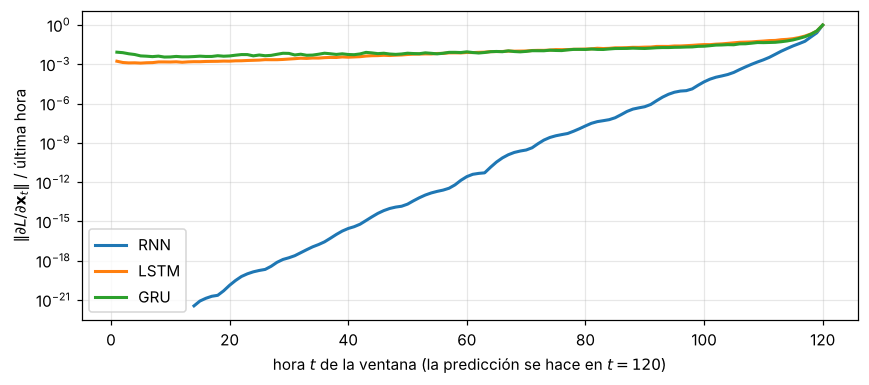

RNN   24 h antes: 9.1e-06 · 96 h antes: 1.4e-19 · primera hora: 0.0e+00
LSTM  24 h antes: 2.5e-02 · 96 h antes: 2.0e-03 · primera hora: 1.7e-03
GRU   24 h antes: 2.0e-02 · 96 h antes: 4.4e-03 · primera hora: 8.5e-03


In [8]:
torch.manual_seed(0)
m_rnn = entrenar(Recurrente(nn.RNN), tr, va)
resultados['rnn'] = {'val': mae(m_rnn, va)}
curvas = {'RNN': gradiente_por_hora(m_rnn), 'LSTM': gradiente_por_hora(m_lstm), 'GRU': gradiente_por_hora(m_gru)}

fig, ax = plt.subplots(figsize=(8, 3.6))
horas = np.arange(1, T + 1)
for nombre, g in curvas.items():
    ax.semilogy(horas, np.where(g > 0, g / g[-1], np.nan), lw=2, label=nombre)
ax.set_xlabel('hora $t$ de la ventana (la predicción se hace en $t = 120$)')
ax.set_ylabel(r'$\Vert \partial L / \partial \mathbf{x}_t \Vert$ / última hora'); ax.legend()
plt.tight_layout(); plt.show()
for nombre, g in curvas.items():
    print(f'{nombre:5s} 24 h antes: {g[T - 25] / g[-1]:.1e} · 96 h antes: {g[T - 97] / g[-1]:.1e} · primera hora: {g[0] / g[-1]:.1e}')

La forma cambia por completo. En la RNN el gradiente cae como una recta en escala logarítmica, el mismo factor repetido hora tras hora, hasta llegar a cero. En la LSTM y la GRU cae rápido en las primeras horas y luego casi se aplana: la señal de hace cinco días sigue llegando, mil veces más débil que la de la última hora, pero no cero. Eso es el camino aditivo: $\partial \mathbf c_t / \partial \mathbf c_{t-1} = \operatorname{diag}(\mathbf f_t)$, sin $W_{hh}$ multiplicando en cada paso.

In [9]:
# Lo que lee la figura S05-F11 (make_s05_figuras_notebooks.py)
np.savez('gradiente_tiempo_lstm_gru.npz', g_rnn=curvas['RNN'], g_lstm=curvas['LSTM'], g_gru=curvas['GRU'])

## 5. LSTM con 1 día frente a 5 días
Si a la LSTM sí le llega gradiente de hace cinco días, ¿le sirven esos días? Misma red con ventanas de 24 horas que terminan en la misma hora.

In [10]:
def recortar(ini, T_nueva):
    return ini + (T - T_nueva)

torch.manual_seed(0)
m_lstm_24 = entrenar(Recurrente(nn.LSTM), recortar(tr, 24), recortar(va, 24), T=24)
resultados['lstm_24h'] = {'val': mae(m_lstm_24, recortar(va, 24), T=24)}
print(f"LSTM con 5 días {resultados['lstm']['val']:.2f} °C · con 1 día {resultados['lstm_24h']['val']:.2f} °C")

época 1: MAE validación 2.399 °C


época 2: MAE validación 2.367 °C


época 3: MAE validación 2.345 °C


época 4: MAE validación 2.350 °C


época 5: MAE validación 2.336 °C


época 6: MAE validación 2.305 °C


época 7: MAE validación 2.318 °C


época 8: MAE validación 2.295 °C
5 s · 2,065 parámetros
LSTM con 5 días 2.32 °C · con 1 día 2.30 °C


Tampoco. Que el gradiente llegue es una condición para poder usar el pasado lejano, no una garantía de que sirva. Para la temperatura de mañana, lo que pasó hace cuatro días dice poco que no diga ya el último día. El camino aditivo importa cuando la tarea **depende** del pasado lejano: un texto en el que una negación al principio cambia el sentido del final (Parte 4), o una fecha que hay que copiar al final de la frase (Parte 5).

## 6. Dos capas y *dropout* entre capas
`num_layers=2`: los $\mathbf h_t$ de la primera capa son los $\mathbf x_t$ de la segunda. `dropout=0.2` apaga unidades **entre** capas; no toca la conexión recurrente (para eso hace falta escribir la celda, *Tu turno*).

In [11]:
torch.manual_seed(0)
m_lstm_2 = entrenar(Recurrente(nn.LSTM, capas=2, dropout=0.2), tr, va)
resultados['lstm_2capas'] = {'val': mae(m_lstm_2, va)}
print(f"LSTM 1 capa {resultados['lstm']['val']:.2f} °C · 2 capas {resultados['lstm_2capas']['val']:.2f} °C")

época 1: MAE validación 2.521 °C


época 2: MAE validación 2.393 °C


época 3: MAE validación 2.405 °C


época 4: MAE validación 2.354 °C


época 5: MAE validación 2.320 °C


época 6: MAE validación 2.320 °C


época 7: MAE validación 2.309 °C


época 8: MAE validación 2.301 °C
42 s · 4,241 parámetros


LSTM 1 capa 2.32 °C · 2 capas 2.30 °C


## Evaluación en prueba
Una sola vez, con la tabla de los tres notebooks.

In [12]:
base_test = float(np.abs(temp[te + T - 1] - temp[te + T - 1 + H_FUT]).mean())
modelos = {'rnn': (m_rnn, te, T), 'lstm': (m_lstm, te, T), 'gru': (m_gru, te, T),
           'lstm_24h': (m_lstm_24, recortar(te, 24), 24), 'lstm_2capas': (m_lstm_2, te, T)}
for k, (m, ini, Tm) in modelos.items():
    resultados[k]['test'] = mae(m, ini, T=Tm)
    resultados[k]['parametros'] = sum(p.numel() for p in m.parameters())
resultados['base'] = {'val': float(base_val), 'test': base_test, 'parametros': 0}
print(f"{'modelo':12s} {'parámetros':>10s} {'validación':>11s} {'prueba':>8s}")
for k in ('base', 'rnn', 'lstm', 'gru', 'lstm_24h', 'lstm_2capas'):
    r = resultados[k]
    print(f"{k:12s} {r['parametros']:10,d} {r['val']:9.2f} °C {r['test']:6.2f} °C")
json.dump(resultados, open('resultados_jena_53.json', 'w'), indent=1)

modelo       parámetros  validación   prueba
base                  0      2.44 °C   2.62 °C
rnn                 529      2.33 °C   2.45 °C
lstm              2,065      2.32 °C   2.49 °C
gru               1,553      2.30 °C   2.46 °C
lstm_24h          2,065      2.30 °C   2.47 °C
lstm_2capas       4,241      2.30 °C   2.46 °C


En prueba, las cuatro redes recurrentes quedan entre 2.45 y 2.49 °C, todas por debajo de la línea base (2.62 °C) y a centésimas entre sí. Esas diferencias son del tamaño de lo que cambia al usar otra semilla: con estos números no se puede decir que una celda le gane a otra en Jena. Lo que sí separa a la RNN de la LSTM y la GRU es la sección 4.

## Tu turno · 15 minutos
1. **El sesgo de la compuerta de olvido.** Inicializa $\mathbf f_t$ cerca de 1 poniendo su sesgo en 1 o en 3 (en PyTorch es el segundo bloque de 16 de `bias_ih_l0`; pon `bias_hh_l0` de ese bloque en 0) y repite la sección 4 **sin entrenar**. ¿Cómo cambia la curva del gradiente?
2. **Una tarea que sí necesita memoria.** Genera secuencias de ruido `x = torch.rand(n, T, 1)` cuyo objetivo sea el **primer** valor, `x[:, 0, 0]`, y entrena RNN, LSTM y GRU con $T = 5$, $20$ y $50$. ¿Cuál aprende con cada $T$? Prueba también la LSTM con el sesgo de olvido del punto 1. Ojo: con pocas épocas, alguna puede quedarse en predecir la media (MAE ≈ 0.25) aunque podría aprender; corre al menos dos semillas antes de concluir.
3. **Dropout recurrente.** Escribe la celda de la sección 1 con una máscara de *dropout* sobre $\mathbf h_{t-1}$ que sea **la misma** en todos los pasos (Gal y Ghahramani, 2016). ¿Cambia el MAE en Jena?

**Para pensar.** En la sección 5 la LSTM no aprovechó los días extra. ¿Qué experimento harías para saber si es porque la tarea no los necesita o porque la red no logra usarlos?

In [13]:
# Tu turno

### Referencias
- Hochreiter y Schmidhuber (1997), *Long Short-Term Memory*, Neural Computation.
- Gers, Schmidhuber y Cummins (2000), *Learning to Forget: Continual Prediction with LSTM*, Neural Computation.
- Cho et al. (2014), *Learning Phrase Representations using RNN Encoder–Decoder for Statistical Machine Translation*, EMNLP (la GRU).
- Jozefowicz, Zaremba y Sutskever (2015), *An Empirical Exploration of Recurrent Network Architectures*, ICML (el sesgo de olvido en 1).
- Gal y Ghahramani (2016), *A Theoretically Grounded Application of Dropout in Recurrent Neural Networks*, NeurIPS.